In [13]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/data-analysis-competition-lhc-for-ict-mu-students/File paths.txt
/kaggle/input/competitions/data-analysis-competition-lhc-for-ict-mu-students/Question.pdf
/kaggle/input/datasets/gundrathishashi/lhc-ml/view


In [14]:

!pip -q install gdown


In [15]:

!pip -q install --upgrade gdown

import gdown
import os

file_id = "1eHChVwaAwG66p9eDhISOROPIvKXnMg9W"

zip_path = "/kaggle/working/Arjun_Assignment_data.zip"

url = f"https://drive.google.com/uc?id={file_id}"

result = gdown.download(
    url=url,
    output=zip_path,
    quiet=False,
    resume=True
)

if result and os.path.isfile(zip_path) and os.path.getsize(zip_path) > 0:
    print("\nSUCCESS: File downloaded")
    print("Size:", round(os.path.getsize(zip_path) / (1024 * 1024), 2), "MB")
else:
    print("\nFAILED: Google Drive did not provide the file.")
    print("Check sharing permissions or Google Drive download limits.")



SUCCESS: File downloaded
Size: 1589.66 MB


Skipping already downloaded file /kaggle/working/Arjun_Assignment_data.zip


In [16]:

import zipfile
import os

zip_path = "/kaggle/working/Arjun_Assignment_data.zip"
extract_dir = "/kaggle/working/Arjun_Assignment_data"

print("Checking ZIP file...")

with zipfile.ZipFile(zip_path, "r") as z:
    print("Number of files:", len(z.namelist()))
    print("Checking archive integrity...")

    bad_file = z.testzip()

    if bad_file:
        print("Corrupted file:", bad_file)
    else:
        print("ZIP integrity: OK")
        z.extractall(extract_dir)
        print("Extraction completed!")

print("\nExtracted directory:", extract_dir)


Checking ZIP file...
Number of files: 3
Checking archive integrity...
ZIP integrity: OK
Extraction completed!

Extracted directory: /kaggle/working/Arjun_Assignment_data


In [17]:

import os

for root, dirs, files in os.walk(extract_dir):
    for file in files:
        print(os.path.join(root, file))


/kaggle/working/Arjun_Assignment_data/Arjun_Assignment_data/dataset-20210607T020316Z-002.zip
/kaggle/working/Arjun_Assignment_data/Arjun_Assignment_data/dataset-20210607T020316Z-003.zip
/kaggle/working/Arjun_Assignment_data/Arjun_Assignment_data/dataset-20210607T020316Z-001.zip


In [18]:

import os
import zipfile

base_dir = "/kaggle/working/Arjun_Assignment_data/Arjun_Assignment_data"

for filename in sorted(os.listdir(base_dir)):
    if filename.endswith(".zip"):
        zip_path = os.path.join(base_dir, filename)
        extract_dir = os.path.join(
            base_dir, filename.replace(".zip", "")
        )

        print(f"\nExtracting: {filename}")

        with zipfile.ZipFile(zip_path, "r") as z:
            print("Files inside:", len(z.namelist()))

            bad_file = z.testzip()
            if bad_file:
                print("Archive error:", bad_file)
                continue

            os.makedirs(extract_dir, exist_ok=True)
            z.extractall(extract_dir)

        print("Extracted to:", extract_dir)

print("\nExtraction process completed.")



Extracting: dataset-20210607T020316Z-001.zip
Files inside: 4
Extracted to: /kaggle/working/Arjun_Assignment_data/Arjun_Assignment_data/dataset-20210607T020316Z-001

Extracting: dataset-20210607T020316Z-002.zip
Files inside: 2
Extracted to: /kaggle/working/Arjun_Assignment_data/Arjun_Assignment_data/dataset-20210607T020316Z-002

Extracting: dataset-20210607T020316Z-003.zip
Files inside: 1
Extracted to: /kaggle/working/Arjun_Assignment_data/Arjun_Assignment_data/dataset-20210607T020316Z-003

Extraction process completed.


In [19]:

import os

base_dir = "/kaggle/working/Arjun_Assignment_data"

for root, dirs, files in os.walk(base_dir):
    level = root.replace(base_dir, "").count(os.sep)
    indent = "  " * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        size = os.path.getsize(os.path.join(root, file))
        print(f"{indent}  {file} ({size / (1024**2):.2f} MB)")


Arjun_Assignment_data/
  Arjun_Assignment_data/
    dataset-20210607T020316Z-002.zip (505.59 MB)
    dataset-20210607T020316Z-003.zip (553.73 MB)
    dataset-20210607T020316Z-001.zip (530.10 MB)
    dataset-20210607T020316Z-001/
      dataset/
        postLinks.json (528.33 MB)
        posts_long.csv (859.17 MB)
        postLinks.csv (310.48 MB)
        posts_short.csv (65.84 MB)
    dataset-20210607T020316Z-003/
      dataset/
        post_history.csv (2040.67 MB)
    dataset-20210607T020316Z-002/
      dataset/
        posts_long.json (977.19 MB)
        users.csv (603.84 MB)


In [20]:
BASE_DIR = "/kaggle/working/Arjun_Assignment_data/Arjun_Assignment_data"

In [21]:

import os
import pandas as pd

BASE_DIR = "/kaggle/working/Arjun_Assignment_data/Arjun_Assignment_data"

files = {
    "posts_short": "dataset-20210607T020316Z-001/dataset/posts_short.csv",
    "posts_long": "dataset-20210607T020316Z-001/dataset/posts_long.csv",
    "users": "dataset-20210607T020316Z-002/dataset/users.csv",
    "post_history": "dataset-20210607T020316Z-003/dataset/post_history.csv",
    "postLinks": "dataset-20210607T020316Z-001/dataset/postLinks.csv",
}

for name, relative_path in files.items():
    path = os.path.join(BASE_DIR, relative_path)

    print(f"\n{'='*50}")
    print("Dataset:", name)
    print("Exists:", os.path.isfile(path))

    if os.path.isfile(path):
        print("Size (MB):", round(os.path.getsize(path) / 1024**2, 2))

        try:
            sample = pd.read_csv(path, nrows=5)
            print("Readable: YES")
            print("Columns:", sample.columns.tolist())
            display(sample.head(2))
        except Exception as e:
            print("Read error:", str(e)[:300])



Dataset: posts_short
Exists: True
Size (MB): 65.84
Readable: YES
Columns: ['Unnamed: 0', 'id', 'post_type_id', 'accepted_answer_id', 'parent_id', 'creation_date', 'score', 'view_count', 'owner_user_id', 'tags', 'answer_count', 'comment_count', 'favorite_count', 'community_owned_date']


,Unnamed: 0,id,post_type_id,accepted_answer_id,parent_id,creation_date,score,view_count,owner_user_id,tags,answer_count,comment_count,favorite_count,community_owned_date
0,0,4,1,7,-999,2008-07-31T21:42:52.667,573,37080,8,<c#><floating-point><type-conversion><double><...,13,1,41,2012-10-31T16:42:47.213
1,1,6,1,31,-999,2008-07-31T22:08:08.620,256,16306,9,<html><css><css3><internet-explorer-7>,5,0,10,NaN



Dataset: posts_long
Exists: True
Size (MB): 859.17
Readable: YES
Columns: ['Unnamed: 0', 'id', 'post_type_id', 'accepted_answer_id', 'parent_id', 'creation_date', 'score', 'view_count', 'owner_user_id', 'tags', 'answer_count', 'comment_count', 'favorite_count', 'community_owned_date', 'title', 'body']


,Unnamed: 0,id,post_type_id,accepted_answer_id,parent_id,creation_date,score,view_count,owner_user_id,tags,answer_count,comment_count,favorite_count,community_owned_date,title,body
0,0,4,1,7,-999,2008-07-31T21:42:52.667,573,37080,8,<c#><floating-point><type-conversion><double><...,13,1,41,2012-10-31T16:42:47.213,Convert Decimal to Double?,<p>I want to use a track-bar to change a form'...
1,1,6,1,31,-999,2008-07-31T22:08:08.620,256,16306,9,<html><css><css3><internet-explorer-7>,5,0,10,NaN,Percentage width child element in absolutely p...,<p>I have an absolutely positioned <code>div</...



Dataset: users
Exists: True
Size (MB): 603.84
Readable: YES
Columns: ['Unnamed: 0', 'id', 'reputation', 'creation_date', 'display_name', 'views', 'upvotes', 'downvotes', 'account_id']


,Unnamed: 0,id,reputation,creation_date,display_name,views,upvotes,downvotes,account_id
0,0,-1,1,2008-07-31T00:00:00.000,Community,649,274835,980920,-1
1,1,1,44300,2008-07-31T14:22:31.287,Jeff Atwood,408587,3367,1309,1



Dataset: post_history
Exists: True
Size (MB): 2040.67
Readable: YES
Columns: ['Unnamed: 0', 'id', 'ph_type_id', 'post_id', 'revision_guid', 'creation_date', 'user_id', 'user_display_name', 'comment', 'text']


,Unnamed: 0,id,ph_type_id,post_id,revision_guid,creation_date,user_id,user_display_name,comment,text
0,0,12,1,17,0421fb42-a29a-4cb2-84ba-a828725410f8,2008-08-01T05:09:55.993,2,NaN,NaN,Binary Data in MYSQL
1,1,13,3,17,0421fb42-a29a-4cb2-84ba-a828725410f8,2008-08-01T05:09:55.993,2,NaN,NaN,<database><mysql>



Dataset: postLinks
Exists: True
Size (MB): 310.48
Readable: YES
Columns: ['Unnamed: 0', 'id', 'creation_date', 'post_id', 'related_post_id', 'link_type_id']


,Unnamed: 0,id,creation_date,post_id,related_post_id,link_type_id
0,0,19,2010-04-26T02:59:48.130,109,32412,1
1,1,37,2010-04-26T02:59:48.600,1970,617600,1


In [22]:

import os

json_files = [
    "dataset-20210607T020316Z-002/dataset/posts_long.json",
    "dataset-20210607T020316Z-001/dataset/postLinks.json",
]

for relative_path in json_files:
    path = os.path.join(BASE_DIR, relative_path)

    print("\nFile:", relative_path)
    print("Exists:", os.path.isfile(path))

    if os.path.isfile(path):
        with open(path, "r", encoding="utf-8") as f:
            first_line = f.readline(1000)

        print("First 1000 characters:")
        print(first_line[:500])



File: dataset-20210607T020316Z-002/dataset/posts_long.json
Exists: True
First 1000 characters:
{"id":{"0":4,"1":6,"2":9,"3":11,"4":13,"5":14,"6":17,"7":24,"8":36,"9":42,"10":48,"11":59,"12":88,"13":90,"14":104,"15":123,"16":126,"17":129,"18":173,"19":180,"20":231,"21":260,"22":289,"23":328,"24":336,"25":361,"26":371,"27":402,"28":549,"29":564,"30":588,"31":609,"32":622,"33":626,"34":650,"35":696,"36":709,"37":752,"38":769,"39":773,"40":871,"41":879,"42":888,"43":972,"44":1005,"45":1033,"46":1037,"47":1040,"48":1108,"49":1160,"50":1276,"51":1304,"52":1383,"53":1408,"54":1457,"55":1476,"56"

File: dataset-20210607T020316Z-001/dataset/postLinks.json
Exists: True
First 1000 characters:
{"id":{"0":19,"1":37,"2":42,"3":48,"4":52,"5":58,"6":59,"7":63,"8":69,"9":70,"10":72,"11":74,"12":75,"13":76,"14":81,"15":84,"16":90,"17":96,"18":119,"19":121,"20":126,"21":128,"22":130,"23":131,"24":134,"25":142,"26":144,"27":149,"28":150,"29":162,"30":164,"31":166,"32":168,"33":170,"34":178,"35":184,"36":

In [23]:

import os
import pandas as pd

BASE_DIR = "/kaggle/working/Arjun_Assignment_data/Arjun_Assignment_data"

FILES = {
    "posts_short": "dataset-20210607T020316Z-001/dataset/posts_short.csv",
    "posts_long": "dataset-20210607T020316Z-001/dataset/posts_long.csv",
    "postLinks": "dataset-20210607T020316Z-001/dataset/postLinks.csv",
    "users": "dataset-20210607T020316Z-002/dataset/users.csv",
    "post_history": "dataset-20210607T020316Z-003/dataset/post_history.csv",
}

for name, relative_path in FILES.items():
    path = os.path.join(BASE_DIR, relative_path)

    print("\n" + "=" * 70)
    print("DATASET:", name)

    if not os.path.isfile(path):
        print("FILE NOT FOUND:", path)
        continue

    print("Size (MB):", round(os.path.getsize(path) / 1024**2, 2))

    try:
        df_sample = pd.read_csv(path, nrows=5, low_memory=False)
        print("Columns:", df_sample.columns.tolist())
        display(df_sample.head(2))
    except Exception as error:
        print("Could not read sample:", repr(error))



DATASET: posts_short
Size (MB): 65.84
Columns: ['Unnamed: 0', 'id', 'post_type_id', 'accepted_answer_id', 'parent_id', 'creation_date', 'score', 'view_count', 'owner_user_id', 'tags', 'answer_count', 'comment_count', 'favorite_count', 'community_owned_date']


,Unnamed: 0,id,post_type_id,accepted_answer_id,parent_id,creation_date,score,view_count,owner_user_id,tags,answer_count,comment_count,favorite_count,community_owned_date
0,0,4,1,7,-999,2008-07-31T21:42:52.667,573,37080,8,<c#><floating-point><type-conversion><double><...,13,1,41,2012-10-31T16:42:47.213
1,1,6,1,31,-999,2008-07-31T22:08:08.620,256,16306,9,<html><css><css3><internet-explorer-7>,5,0,10,NaN



DATASET: posts_long
Size (MB): 859.17
Columns: ['Unnamed: 0', 'id', 'post_type_id', 'accepted_answer_id', 'parent_id', 'creation_date', 'score', 'view_count', 'owner_user_id', 'tags', 'answer_count', 'comment_count', 'favorite_count', 'community_owned_date', 'title', 'body']


,Unnamed: 0,id,post_type_id,accepted_answer_id,parent_id,creation_date,score,view_count,owner_user_id,tags,answer_count,comment_count,favorite_count,community_owned_date,title,body
0,0,4,1,7,-999,2008-07-31T21:42:52.667,573,37080,8,<c#><floating-point><type-conversion><double><...,13,1,41,2012-10-31T16:42:47.213,Convert Decimal to Double?,<p>I want to use a track-bar to change a form'...
1,1,6,1,31,-999,2008-07-31T22:08:08.620,256,16306,9,<html><css><css3><internet-explorer-7>,5,0,10,NaN,Percentage width child element in absolutely p...,<p>I have an absolutely positioned <code>div</...



DATASET: postLinks
Size (MB): 310.48
Columns: ['Unnamed: 0', 'id', 'creation_date', 'post_id', 'related_post_id', 'link_type_id']


,Unnamed: 0,id,creation_date,post_id,related_post_id,link_type_id
0,0,19,2010-04-26T02:59:48.130,109,32412,1
1,1,37,2010-04-26T02:59:48.600,1970,617600,1



DATASET: users
Size (MB): 603.84
Columns: ['Unnamed: 0', 'id', 'reputation', 'creation_date', 'display_name', 'views', 'upvotes', 'downvotes', 'account_id']


,Unnamed: 0,id,reputation,creation_date,display_name,views,upvotes,downvotes,account_id
0,0,-1,1,2008-07-31T00:00:00.000,Community,649,274835,980920,-1
1,1,1,44300,2008-07-31T14:22:31.287,Jeff Atwood,408587,3367,1309,1



DATASET: post_history
Size (MB): 2040.67
Columns: ['Unnamed: 0', 'id', 'ph_type_id', 'post_id', 'revision_guid', 'creation_date', 'user_id', 'user_display_name', 'comment', 'text']


,Unnamed: 0,id,ph_type_id,post_id,revision_guid,creation_date,user_id,user_display_name,comment,text
0,0,12,1,17,0421fb42-a29a-4cb2-84ba-a828725410f8,2008-08-01T05:09:55.993,2,NaN,NaN,Binary Data in MYSQL
1,1,13,3,17,0421fb42-a29a-4cb2-84ba-a828725410f8,2008-08-01T05:09:55.993,2,NaN,NaN,<database><mysql>


In [24]:

# Mining Duplicate Questions in Stack Overflow

## Q1. Determine the Number of Tags Per Question

**Objective:** To calculate the number of tags associated with each Stack Overflow question and analyse the distribution of tags per question.


SyntaxError: invalid syntax (3067499370.py, line 5)

In [25]:

## Q2. Determine the Total Number of Unique Tags

**Objective:** To identify and count the distinct tags used across all Stack Overflow questions.


SyntaxError: invalid syntax (3424597586.py, line 3)

Total question records: 676204
Questions with at least one tag: 676204
Questions without tags: 0

Tags per question — descriptive statistics:


count    676204.000000
mean          2.840928
std           1.197084
min           1.000000
25%           2.000000
50%           3.000000
75%           4.000000
max           6.000000
Name: tag_count, dtype: float64


Number of questions for each tag count:


,Number of questions
Number of tags,
1,94523
2,189704
3,194334
4,124127
5,73490
6,26


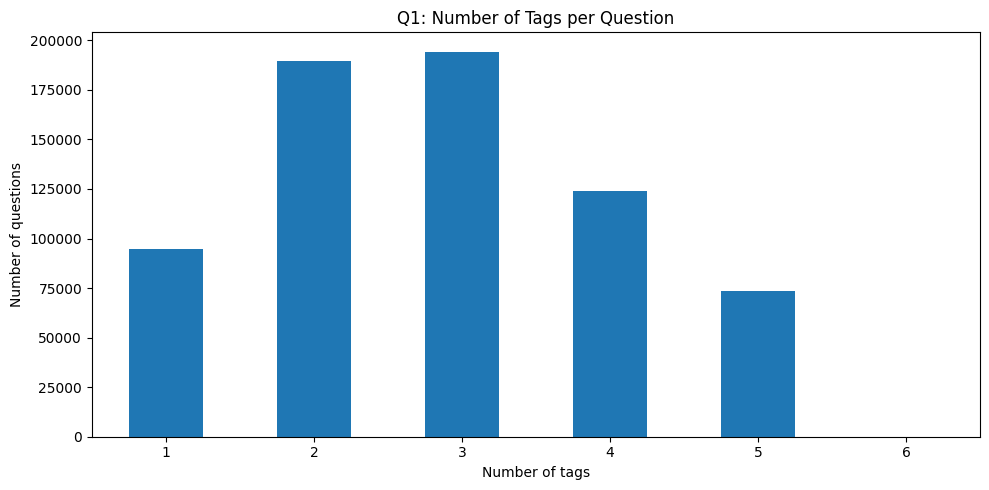

In [26]:

import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

BASE_DIR = "/kaggle/working/Arjun_Assignment_data/Arjun_Assignment_data"

POSTS_PATH = os.path.join(
    BASE_DIR,
    "dataset-20210607T020316Z-001/dataset/posts_short.csv"
)

# Load only the columns required for tag analysis
posts = pd.read_csv(
    POSTS_PATH,
    usecols=["id", "post_type_id", "creation_date", "owner_user_id", "tags"],
    low_memory=False
)

# Keep questions only
questions = posts.loc[
    pd.to_numeric(posts["post_type_id"], errors="coerce") == 1
].copy()

# Extract tags from strings such as <python><pandas><dataframe>
def extract_tags(value):
    if pd.isna(value):
        return []
    return re.findall(r"<([^<>]+)>", str(value))

questions["tag_list"] = questions["tags"].apply(extract_tags)
questions["tag_count"] = questions["tag_list"].str.len()

print("Total question records:", len(questions))
print("Questions with at least one tag:", (questions["tag_count"] > 0).sum())
print("Questions without tags:", (questions["tag_count"] == 0).sum())

print("\nTags per question — descriptive statistics:")
display(questions["tag_count"].describe())

print("\nNumber of questions for each tag count:")
tag_count_distribution = questions["tag_count"].value_counts().sort_index()
display(tag_count_distribution.rename_axis("Number of tags").to_frame("Number of questions"))

plt.figure(figsize=(10, 5))
tag_count_distribution.plot(kind="bar")
plt.title("Q1: Number of Tags per Question")
plt.xlabel("Number of tags")
plt.ylabel("Number of questions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:

## Q2. Determine the Total Number of Unique Tags

**Objective:** To identify and count the distinct tags used across all Stack Overflow questions.


In [27]:

from collections import Counter

tag_frequency = Counter(
    tag
    for tag_list in questions["tag_list"]
    for tag in tag_list
)

print("Total unique tags:", len(tag_frequency))
print("Total tag assignments:", sum(tag_frequency.values()))

print("\nTop 10 tags:")
display(
    pd.DataFrame(
        tag_frequency.most_common(10),
        columns=["Tag", "Frequency"]
    )
)


Total unique tags: 25310
Total tag assignments: 1921047

Top 10 tags:


,Tag,Frequency
0,java,94846
1,javascript,81346
2,php,65333
3,c#,61899
4,python,61505
5,c++,40158
6,android,39910
7,html,33736
8,jquery,32601
9,mysql,24765


Top 25 most frequent tags:


,Tag,Frequency
0,java,94846
1,javascript,81346
2,php,65333
3,c#,61899
4,python,61505
5,c++,40158
6,android,39910
7,html,33736
8,jquery,32601
9,mysql,24765


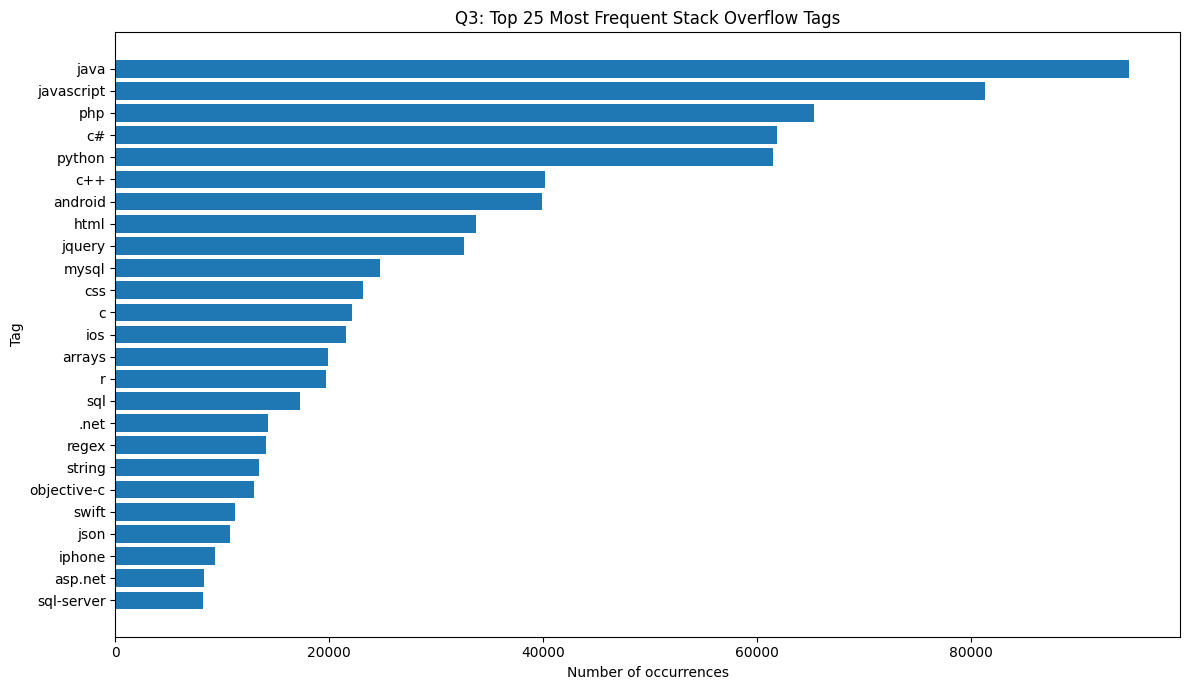

In [28]:

top25 = pd.DataFrame(
    tag_frequency.most_common(25),
    columns=["Tag", "Frequency"]
)

print("Top 25 most frequent tags:")
display(top25)

plt.figure(figsize=(12, 7))
plt.barh(top25["Tag"][::-1], top25["Frequency"][::-1])
plt.title("Q3: Top 25 Most Frequent Stack Overflow Tags")
plt.xlabel("Number of occurrences")
plt.ylabel("Tag")
plt.tight_layout()
plt.show()


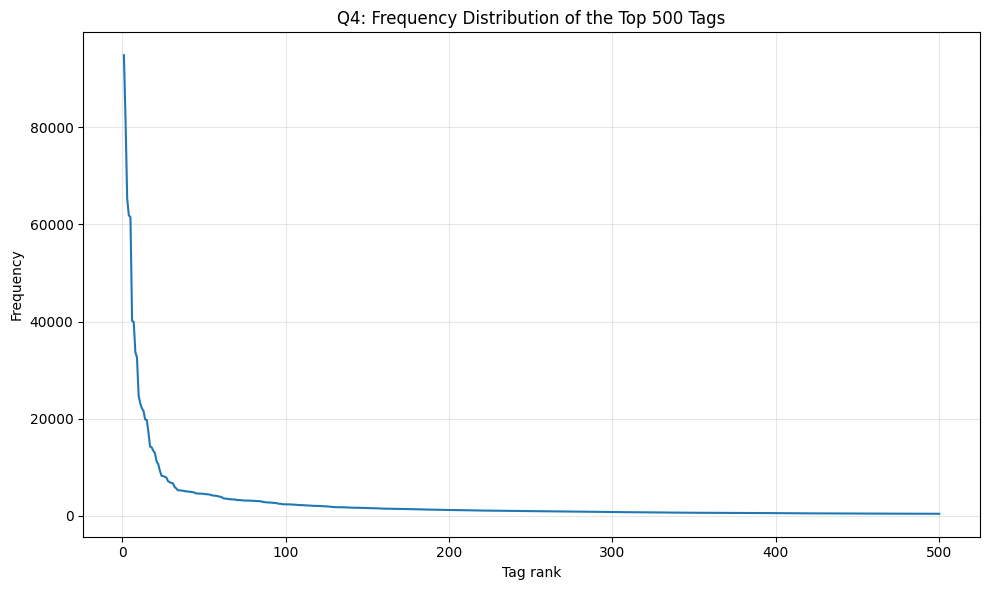

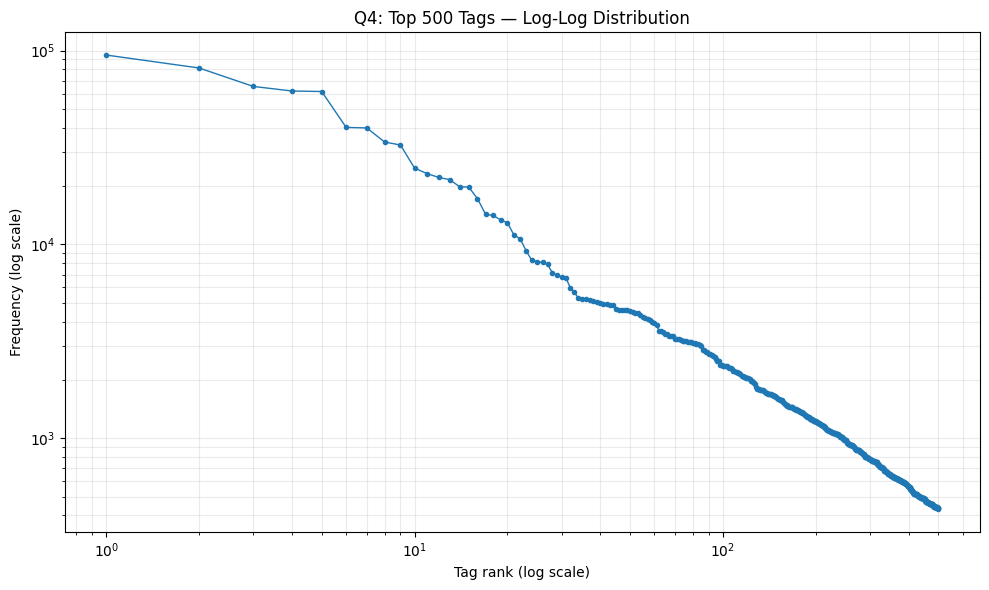

Number of tags plotted: 500
Most frequent tag: java
Frequency of most frequent tag: 94846
Frequency of rank-500 tag: 430


In [29]:

top500 = pd.DataFrame(
    tag_frequency.most_common(500),
    columns=["Tag", "Frequency"]
)

top500["Rank"] = np.arange(1, len(top500) + 1)

plt.figure(figsize=(10, 6))
plt.plot(top500["Rank"], top500["Frequency"], linewidth=1.5)
plt.title("Q4: Frequency Distribution of the Top 500 Tags")
plt.xlabel("Tag rank")
plt.ylabel("Frequency")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
plt.loglog(top500["Rank"], top500["Frequency"], marker=".", linewidth=1)
plt.title("Q4: Top 500 Tags — Log-Log Distribution")
plt.xlabel("Tag rank (log scale)")
plt.ylabel("Frequency (log scale)")
plt.grid(True, which="both", alpha=0.25)
plt.tight_layout()
plt.show()

print("Number of tags plotted:", len(top500))
print("Most frequent tag:", top500.iloc[0]["Tag"])
print("Frequency of most frequent tag:", top500.iloc[0]["Frequency"])
print("Frequency of rank-500 tag:", top500.iloc[-1]["Frequency"])


Period: January 2008 to December 2018
Total questions: 676204
Questions marked as duplicates: 399974


,total_questions,duplicate_questions,duplicate_ratio_percent
month,,,
2008-01,0,0,0.000000
2008-02,0,0,0.000000
2008-03,0,0,0.000000
2008-04,0,0,0.000000
2008-05,0,0,0.000000
2008-06,0,0,0.000000
2008-07,4,0,0.000000
2008-08,816,30,3.676471
2008-09,2399,120,5.002084


,total_questions,duplicate_questions,duplicate_ratio_percent
month,,,
2018-01,8166,7376,90.325741
2018-02,7473,6823,91.302021
2018-03,8320,7621,91.598558
2018-04,7980,7381,92.493734
2018-05,8172,7565,92.572198
2018-06,7280,6795,93.337912
2018-07,7332,6908,94.217130
2018-08,9227,8910,96.564430
2018-09,179,176,98.324022


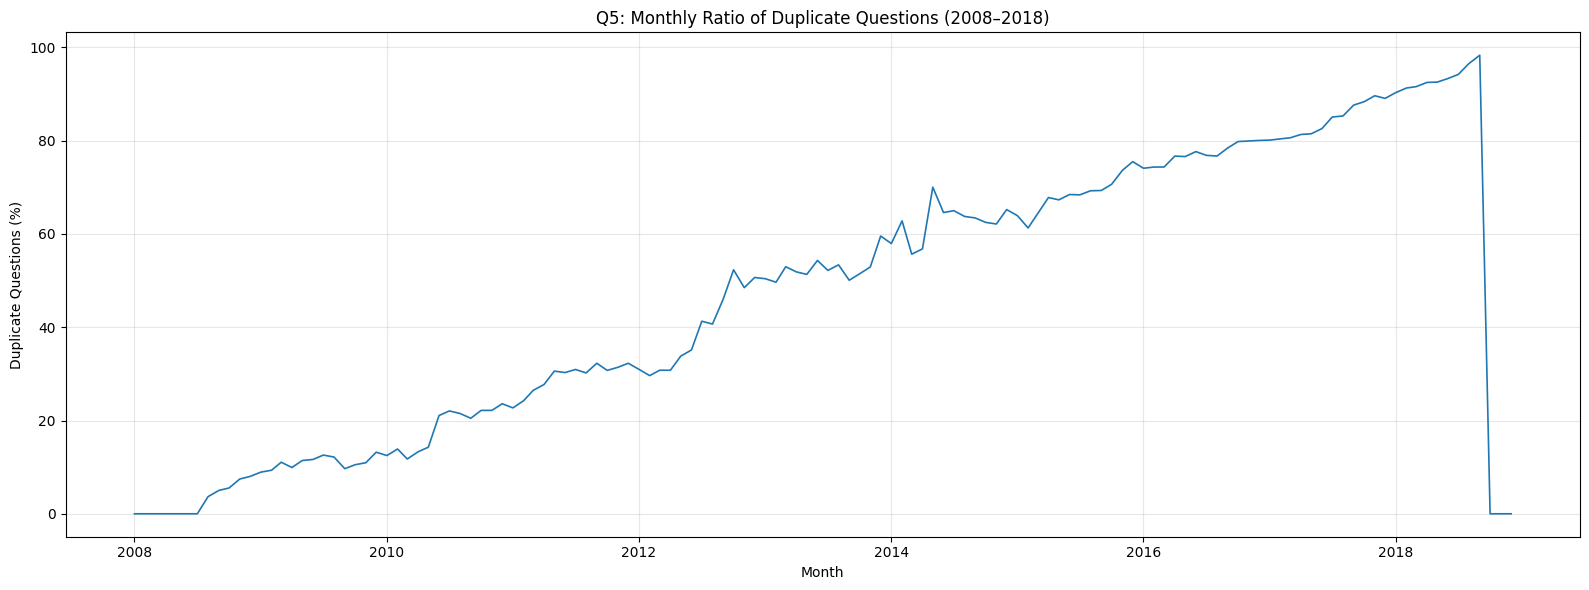

In [30]:

import os
import pandas as pd
import matplotlib.pyplot as plt

BASE_DIR = "/kaggle/working/Arjun_Assignment_data/Arjun_Assignment_data"

POSTS_PATH = os.path.join(
    BASE_DIR,
    "dataset-20210607T020316Z-001/dataset/posts_short.csv"
)

LINKS_PATH = os.path.join(
    BASE_DIR,
    "dataset-20210607T020316Z-001/dataset/postLinks.csv"
)

# --------------------------------------------------
# 1. Load question IDs and creation dates
# --------------------------------------------------
posts = pd.read_csv(
    POSTS_PATH,
    usecols=["id", "post_type_id", "creation_date"],
    low_memory=False
)

posts["post_type_id"] = pd.to_numeric(
    posts["post_type_id"], errors="coerce"
)

posts["creation_date"] = pd.to_datetime(
    posts["creation_date"], errors="coerce", utc=True
)

questions = posts.loc[
    (posts["post_type_id"] == 1) &
    posts["creation_date"].notna()
].copy()

# Keep the requested period: 2008 through 2018 inclusive
questions = questions[
    (questions["creation_date"] >= "2008-01-01") &
    (questions["creation_date"] < "2019-01-01")
].copy()

# --------------------------------------------------
# 2. Identify duplicate links
# --------------------------------------------------
links = pd.read_csv(
    LINKS_PATH,
    usecols=["post_id", "related_post_id", "link_type_id"],
    low_memory=False
)

links["link_type_id"] = pd.to_numeric(
    links["link_type_id"], errors="coerce"
)

duplicate_links = links.loc[
    links["link_type_id"] == 3,
    ["post_id", "related_post_id"]
].copy()

# In Stack Overflow data, post_id is the duplicate/source
# question and related_post_id is the master/target question.
duplicate_ids = set(
    pd.to_numeric(
        duplicate_links["post_id"], errors="coerce"
    ).dropna().astype("int64")
)

# Match duplicate IDs to their original question records
questions["id"] = pd.to_numeric(
    questions["id"], errors="coerce"
)

questions = questions.dropna(subset=["id"])
questions["id"] = questions["id"].astype("int64")

questions["is_duplicate"] = questions["id"].isin(duplicate_ids)

# --------------------------------------------------
# 3. Calculate monthly ratio
# --------------------------------------------------
questions["month"] = (
    questions["creation_date"]
    .dt.tz_convert(None)
    .dt.to_period("M")
)

monthly = questions.groupby("month").agg(
    total_questions=("id", "nunique"),
    duplicate_questions=("is_duplicate", "sum")
)

monthly["duplicate_ratio_percent"] = (
    monthly["duplicate_questions"] /
    monthly["total_questions"] * 100
)

# Include all months in the requested period
all_months = pd.period_range(
    "2008-01", "2018-12", freq="M"
)

monthly = monthly.reindex(all_months, fill_value=0)
monthly.index.name = "month"

print("Period: January 2008 to December 2018")
print("Total questions:", int(monthly["total_questions"].sum()))
print("Questions marked as duplicates:", int(
    monthly["duplicate_questions"].sum()
))

display(monthly.head(12))
display(monthly.tail(12))

# --------------------------------------------------
# 4. Plot monthly trend
# --------------------------------------------------
plt.figure(figsize=(16, 6))

plt.plot(
    monthly.index.to_timestamp(),
    monthly["duplicate_ratio_percent"],
    linewidth=1.2
)

plt.title(
    "Q5: Monthly Ratio of Duplicate Questions (2008–2018)"
)
plt.xlabel("Month")
plt.ylabel("Duplicate Questions (%)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Total unique tags analysed: 25310
Tags with at least 100 questions: 1722

Top 20 tags by duplicate-question percentage:


,tag,total_questions,duplicate_questions,duplicate_percentage
0,nullreferenceexception,505,475,94.06
1,nullpointerexception,2373,2122,89.42
2,python-3.6,183,152,83.06
3,jsf-2.2,211,174,82.46
4,contact,106,87,82.08
5,server,342,277,80.99
6,mariadb,156,126,80.77
7,indexoutofboundsexception,290,234,80.69
8,frontend,136,109,80.15
9,mysqli,3050,2439,79.97


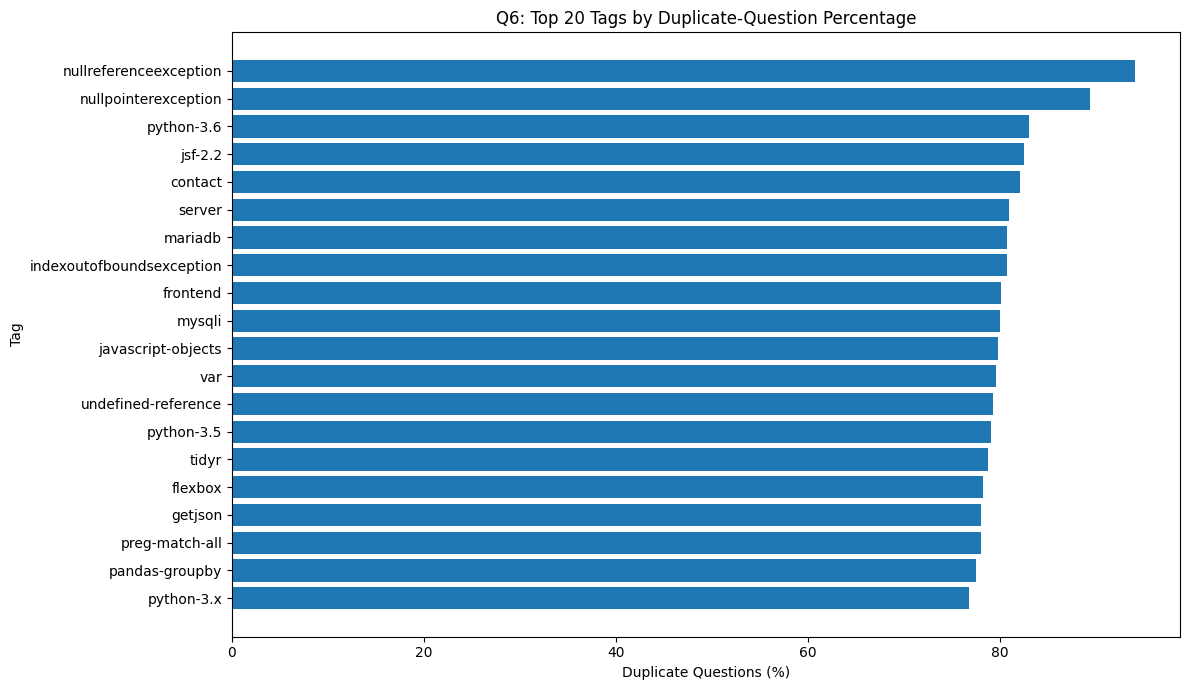

In [31]:

import os
import re
import pandas as pd
import matplotlib.pyplot as plt

BASE_DIR = "/kaggle/working/Arjun_Assignment_data/Arjun_Assignment_data"

POSTS_PATH = os.path.join(
    BASE_DIR,
    "dataset-20210607T020316Z-001/dataset/posts_short.csv"
)

LINKS_PATH = os.path.join(
    BASE_DIR,
    "dataset-20210607T020316Z-001/dataset/postLinks.csv"
)

# --------------------------------------------------
# 1. Load question data
# --------------------------------------------------
posts = pd.read_csv(
    POSTS_PATH,
    usecols=["id", "post_type_id", "tags"],
    low_memory=False
)

posts["post_type_id"] = pd.to_numeric(
    posts["post_type_id"], errors="coerce"
)

questions = posts.loc[
    posts["post_type_id"] == 1
].copy()

questions["id"] = pd.to_numeric(
    questions["id"], errors="coerce"
)

questions = questions.dropna(subset=["id"])
questions["id"] = questions["id"].astype("int64")

# --------------------------------------------------
# 2. Identify duplicate question IDs
# --------------------------------------------------
links = pd.read_csv(
    LINKS_PATH,
    usecols=["post_id", "link_type_id"],
    low_memory=False
)

links["link_type_id"] = pd.to_numeric(
    links["link_type_id"], errors="coerce"
)

duplicate_ids = set(
    pd.to_numeric(
        links.loc[links["link_type_id"] == 3, "post_id"],
        errors="coerce"
    ).dropna().astype("int64")
)

questions["is_duplicate"] = questions["id"].isin(
    duplicate_ids
)

# --------------------------------------------------
# 3. Extract tags and calculate tag-level statistics
# --------------------------------------------------
questions["tag_list"] = questions["tags"].apply(
    lambda x: re.findall(r"<([^<>]+)>", str(x))
    if pd.notna(x) else []
)

tag_data = questions[
    ["id", "is_duplicate", "tag_list"]
].explode("tag_list")

tag_data = tag_data.dropna(subset=["tag_list"])

tag_stats = tag_data.groupby("tag_list").agg(
    total_questions=("id", "nunique"),
    duplicate_questions=("is_duplicate", "sum")
)

tag_stats["duplicate_percentage"] = (
    tag_stats["duplicate_questions"] /
    tag_stats["total_questions"] * 100
)

# Avoid tags with too few questions dominating the ranking.
# Require at least 100 questions per tag for a more stable comparison.
eligible_tags = tag_stats[
    tag_stats["total_questions"] >= 100
].copy()

top20 = eligible_tags.sort_values(
    "duplicate_percentage", ascending=False
).head(20)

top20 = top20.reset_index().rename(
    columns={"tag_list": "tag"}
)

print("Total unique tags analysed:", len(tag_stats))
print("Tags with at least 100 questions:", len(eligible_tags))
print("\nTop 20 tags by duplicate-question percentage:")
display(top20.round(2))

# --------------------------------------------------
# 4. Plot the top 20 tags
# --------------------------------------------------
plt.figure(figsize=(12, 7))

plt.barh(
    top20["tag"][::-1],
    top20["duplicate_percentage"][::-1]
)

plt.title(
    "Q6: Top 20 Tags by Duplicate-Question Percentage"
)
plt.xlabel("Duplicate Questions (%)")
plt.ylabel("Tag")
plt.tight_layout()
plt.show()


Questions with recorded duplicate links: 631227
Duplicate-linked questions with creation dates: 399974

Sample close-event comments and text:


,ph_type_id,comment,text
0,10,1,"{""OriginalQuestionIds"":[7074],""Voters"":[{""Id"":..."
1,10,1,"{""OriginalQuestionIds"":[58119],""Voters"":[{""Id""..."
2,10,1,"{""OriginalQuestionIds"":[5727,96285,92001],""Vot..."
3,10,1,"{""OriginalQuestionIds"":[167343,150129],""Voters..."
4,10,1,"{""OriginalQuestionIds"":[74148],""Voters"":[{""Id""..."
5,10,1,"{""OriginalQuestionIds"":[197182,628744,5664071]..."
6,10,1,"{""OriginalQuestionIds"":[650],""Voters"":[{""Id"":9..."
7,10,1,"{""OriginalQuestionIds"":[174198],""Voters"":[{""Id..."
8,10,1,"{""OriginalQuestionIds"":[22623],""Voters"":[{""Id""..."
9,10,1,"{""OriginalQuestionIds"":[183406],""Voters"":[{""Id..."



Close events with duplicate-related metadata: 34566

Questions with calculable closure time: 34565

Closure-time summary (hours):


count    34565.000000
mean       653.804952
std       4601.324793
min          0.009212
25%          0.377741
50%          1.678913
75%         20.861164
max      81948.885592
Name: hours_to_close, dtype: float64

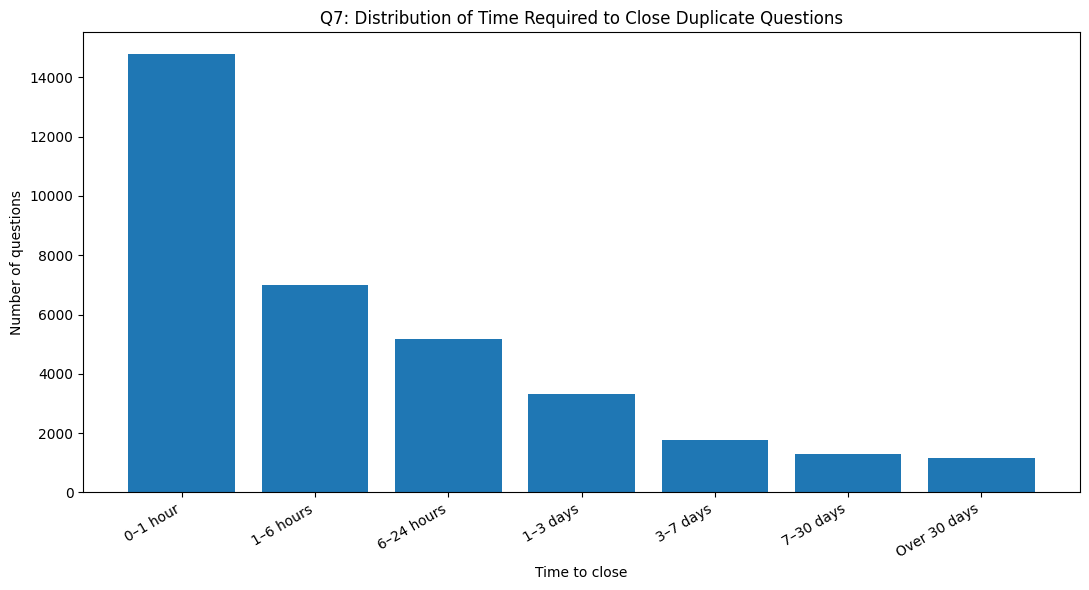

,Number of questions
closure_interval,
0–1 hour,14783
1–6 hours,7013
6–24 hours,5190
1–3 days,3332
3–7 days,1783
7–30 days,1297
Over 30 days,1167


In [32]:

import os
import pandas as pd
import matplotlib.pyplot as plt

BASE_DIR = "/kaggle/working/Arjun_Assignment_data/Arjun_Assignment_data"

POSTS_PATH = os.path.join(
    BASE_DIR,
    "dataset-20210607T020316Z-001/dataset/posts_short.csv"
)

LINKS_PATH = os.path.join(
    BASE_DIR,
    "dataset-20210607T020316Z-001/dataset/postLinks.csv"
)

HISTORY_PATH = os.path.join(
    BASE_DIR,
    "dataset-20210607T020316Z-003/dataset/post_history.csv"
)

# --------------------------------------------------
# 1. Identify duplicate question IDs
# --------------------------------------------------
links = pd.read_csv(
    LINKS_PATH,
    usecols=["post_id", "link_type_id"]
)

links["link_type_id"] = pd.to_numeric(
    links["link_type_id"], errors="coerce"
)

duplicate_ids = set(
    pd.to_numeric(
        links.loc[links["link_type_id"] == 3, "post_id"],
        errors="coerce"
    ).dropna().astype("int64")
)

print("Questions with recorded duplicate links:", len(duplicate_ids))

# --------------------------------------------------
# 2. Read question creation timestamps
# --------------------------------------------------
posts = pd.read_csv(
    POSTS_PATH,
    usecols=["id", "post_type_id", "creation_date"]
)

posts["post_type_id"] = pd.to_numeric(
    posts["post_type_id"], errors="coerce"
)

posts = posts[posts["post_type_id"] == 1].copy()
posts["id"] = pd.to_numeric(posts["id"], errors="coerce")
posts = posts.dropna(subset=["id"])
posts["id"] = posts["id"].astype("int64")

posts = posts[posts["id"].isin(duplicate_ids)].copy()

posts["creation_date"] = pd.to_datetime(
    posts["creation_date"], errors="coerce", utc=True
)

posts = posts.dropna(subset=["creation_date"])
posts = posts.rename(columns={"id": "post_id"})

print("Duplicate-linked questions with creation dates:", len(posts))

# --------------------------------------------------
# 3. Inspect history event types for these questions
# --------------------------------------------------
# Read only relevant columns in chunks to limit RAM use.
history_columns = [
    "post_id", "ph_type_id", "creation_date", "comment", "text"
]

history_chunks = []

for chunk in pd.read_csv(
    HISTORY_PATH,
    usecols=history_columns,
    chunksize=500_000,
    low_memory=False
):
    chunk["post_id"] = pd.to_numeric(
        chunk["post_id"], errors="coerce"
    )
    chunk["ph_type_id"] = pd.to_numeric(
        chunk["ph_type_id"], errors="coerce"
    )

    # Keep close events for duplicate-linked questions
    chunk = chunk[
        chunk["post_id"].isin(duplicate_ids) &
        (chunk["ph_type_id"] == 10)
    ].copy()

    if not chunk.empty:
        history_chunks.append(chunk)

if not history_chunks:
    print(
        "No close-history events were found for the identified "
        "duplicate-linked questions. A closure-time chart cannot "
        "be reliably calculated from these records."
    )
else:
    close_events = pd.concat(history_chunks, ignore_index=True)

    close_events["creation_date"] = pd.to_datetime(
        close_events["creation_date"],
        errors="coerce",
        utc=True
    )

    close_events = close_events.dropna(subset=["creation_date"])

    # Inspect close-event metadata before assuming every event
    # is specifically a duplicate closure.
    print("\nSample close-event comments and text:")
    display(close_events[["ph_type_id", "comment", "text"]].head(10))

    # Use the first recorded close event per question.
    close_events = close_events.sort_values("creation_date")
    first_close = close_events.drop_duplicates(
        subset=["post_id"], keep="first"
    )

    # Verify duplicate-close evidence in event metadata.
    metadata = (
        first_close["comment"].fillna("").astype(str) + " " +
        first_close["text"].fillna("").astype(str)
    )

    duplicate_close_mask = metadata.str.contains(
        r"duplicate|duplicat",
        case=False,
        regex=True
    )

    verified_closures = first_close[duplicate_close_mask].copy()

    print(
        "\nClose events with duplicate-related metadata:",
        len(verified_closures)
    )

    if verified_closures.empty:
        print(
            "No duplicate-specific close metadata was found. "
            "Do not interpret all close events as duplicate closures. "
            "Inspect the event records and schema before proceeding."
        )
    else:
        merged = posts.merge(
            verified_closures[["post_id", "creation_date"]],
            on="post_id",
            how="inner",
            suffixes=("_question", "_closure")
        )

        merged["hours_to_close"] = (
            merged["creation_date_closure"] -
            merged["creation_date_question"]
        ).dt.total_seconds() / 3600

        # Exclude invalid or negative intervals
        merged = merged[
            merged["hours_to_close"].notna() &
            (merged["hours_to_close"] >= 0)
        ].copy()

        print("\nQuestions with calculable closure time:", len(merged))
        print("\nClosure-time summary (hours):")
        display(merged["hours_to_close"].describe())

        # Bar chart of median closure time by interval
        bins = [0, 1, 6, 24, 72, 168, 720, float("inf")]
        labels = [
            "0–1 hour", "1–6 hours", "6–24 hours",
            "1–3 days", "3–7 days", "7–30 days", "Over 30 days"
        ]

        merged["closure_interval"] = pd.cut(
            merged["hours_to_close"],
            bins=bins,
            labels=labels,
            right=True,
            include_lowest=True
        )

        interval_counts = (
            merged["closure_interval"]
            .value_counts(sort=False)
        )

        plt.figure(figsize=(11, 6))
        plt.bar(
            interval_counts.index.astype(str),
            interval_counts.values
        )
        plt.title("Q7: Distribution of Time Required to Close Duplicate Questions")
        plt.xlabel("Time to close")
        plt.ylabel("Number of questions")
        plt.xticks(rotation=30, ha="right")
        plt.tight_layout()
        plt.show()

        display(interval_counts.rename("Number of questions").to_frame())


Duplicate-linked question IDs: 631227
Duplicate questions with known owners: 399974

Reputation distribution:


,Number of users,Percentage
reputation_category,,
1–100,172586,60.64
"101–1,000",74467,26.16
"1,001–10,000",32826,11.53
"10,001–100,000",4498,1.58
"Above 100,000",234,0.08



Total distinct users analysed: 284611


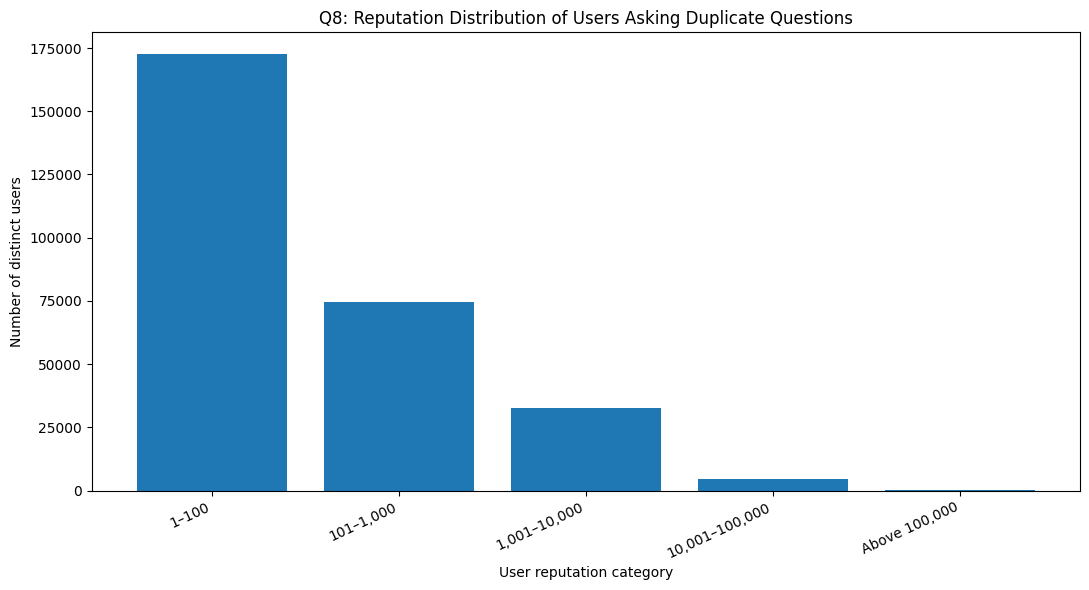

In [35]:

import os
import pandas as pd
import matplotlib.pyplot as plt

BASE_DIR = "/kaggle/working/Arjun_Assignment_data/Arjun_Assignment_data"

POSTS_PATH = os.path.join(
    BASE_DIR,
    "dataset-20210607T020316Z-001/dataset/posts_short.csv"
)

LINKS_PATH = os.path.join(
    BASE_DIR,
    "dataset-20210607T020316Z-001/dataset/postLinks.csv"
)

USERS_PATH = os.path.join(
    BASE_DIR,
    "dataset-20210607T020316Z-002/dataset/users.csv"
)

# --------------------------------------------------
# 1. Identify duplicate question IDs
# --------------------------------------------------
links = pd.read_csv(
    LINKS_PATH,
    usecols=["post_id", "link_type_id"]
)

links["link_type_id"] = pd.to_numeric(
    links["link_type_id"], errors="coerce"
)

duplicate_ids = set(
    pd.to_numeric(
        links.loc[links["link_type_id"] == 3, "post_id"],
        errors="coerce"
    ).dropna().astype("int64")
)

print("Duplicate-linked question IDs:", len(duplicate_ids))

# --------------------------------------------------
# 2. Find owners of duplicate questions
# --------------------------------------------------
posts = pd.read_csv(
    POSTS_PATH,
    usecols=["id", "post_type_id", "owner_user_id"]
)

posts["post_type_id"] = pd.to_numeric(
    posts["post_type_id"], errors="coerce"
)

posts = posts[posts["post_type_id"] == 1].copy()

posts["id"] = pd.to_numeric(posts["id"], errors="coerce")
posts["owner_user_id"] = pd.to_numeric(
    posts["owner_user_id"], errors="coerce"
)

posts = posts.dropna(subset=["id"])
posts["id"] = posts["id"].astype("int64")

duplicate_questions = posts[
    posts["id"].isin(duplicate_ids)
].copy()

# Exclude deleted, anonymous, or missing owners
duplicate_questions = duplicate_questions.dropna(
    subset=["owner_user_id"]
)

duplicate_questions["owner_user_id"] = (
    duplicate_questions["owner_user_id"].astype("int64")
)

print(
    "Duplicate questions with known owners:",
    len(duplicate_questions)
)

# --------------------------------------------------
# 3. Load user reputation and join
# --------------------------------------------------
users = pd.read_csv(
    USERS_PATH,
    usecols=["id", "reputation"]
)

users["id"] = pd.to_numeric(users["id"], errors="coerce")
users["reputation"] = pd.to_numeric(
    users["reputation"], errors="coerce"
)

users = users.dropna(subset=["id", "reputation"])
users["id"] = users["id"].astype("int64")

user_reputation = users.drop_duplicates(
    subset=["id"]
)

result = duplicate_questions.merge(
    user_reputation,
    left_on="owner_user_id",
    right_on="id",
    how="inner"
)

# Use distinct users so users with multiple duplicate questions
# are counted only once in the main reputation distribution.
unique_users = result.drop_duplicates(
    subset=["owner_user_id"]
).copy()

unique_users = unique_users[
    unique_users["reputation"] >= 1
].copy()

# --------------------------------------------------
# 4. Categorize reputation
# --------------------------------------------------
bins = [0, 100, 1000, 10000, 100000, float("inf")]

labels = [
    "1–100",
    "101–1,000",
    "1,001–10,000",
    "10,001–100,000",
    "Above 100,000"
]

unique_users["reputation_category"] = pd.cut(
    unique_users["reputation"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

category_counts = (
    unique_users["reputation_category"]
    .value_counts(sort=False)
)

summary = category_counts.rename(
    "Number of users"
).to_frame()

summary["Percentage"] = (
    summary["Number of users"] /
    summary["Number of users"].sum() * 100
)

print("\nReputation distribution:")
display(summary.round(2))

print("\nTotal distinct users analysed:", len(unique_users))

# --------------------------------------------------
# 5. Plot the bar chart
# --------------------------------------------------
plt.figure(figsize=(11, 6))

plt.bar(
    category_counts.index.astype(str),
    category_counts.values
)

plt.title(
    "Q8: Reputation Distribution of Users Asking Duplicate Questions"
)

plt.xlabel("User reputation category")
plt.ylabel("Number of distinct users")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


Q9 RESULTS
----------------------------------------
Total questions: 676204
Questions covered: 662549
Questions not covered: 13655
Coverage by top 500 tags: 97.98%
Not covered: 2.02%


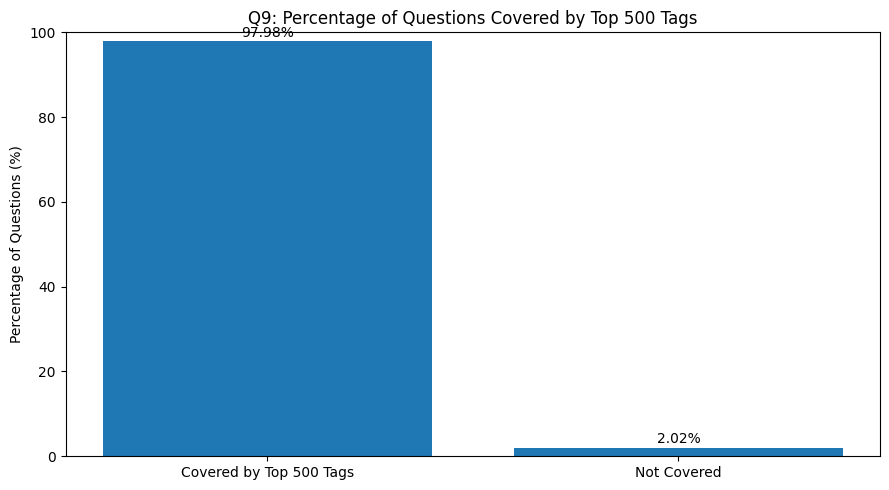

In [36]:

import os
import re
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

BASE_DIR = "/kaggle/working/Arjun_Assignment_data/Arjun_Assignment_data"

POSTS_PATH = os.path.join(
    BASE_DIR,
    "dataset-20210607T020316Z-001/dataset/posts_short.csv"
)

# 1. Load questions
posts = pd.read_csv(
    POSTS_PATH,
    usecols=["id", "post_type_id", "tags"],
    low_memory=False
)

posts["post_type_id"] = pd.to_numeric(
    posts["post_type_id"], errors="coerce"
)

questions = posts[posts["post_type_id"] == 1].copy()

# 2. Extract tags
def extract_tags(value):
    if pd.isna(value):
        return []
    return re.findall(r"<([^<>]+)>", str(value))

questions["tag_list"] = questions["tags"].apply(extract_tags)

# 3. Count tag frequencies (each tag counted once per question)
tag_frequency = Counter(
    tag
    for tag_list in questions["tag_list"]
    for tag in set(tag_list)
)

top500_tags = {
    tag for tag, count in tag_frequency.most_common(500)
}

# 4. Calculate question coverage
questions["covered"] = questions["tag_list"].apply(
    lambda tags: bool(set(tags) & top500_tags)
)

total_questions = len(questions)
covered = int(questions["covered"].sum())
not_covered = total_questions - covered

covered_pct = covered / total_questions * 100 if total_questions else 0
not_covered_pct = 100 - covered_pct if total_questions else 0

print("Q9 RESULTS")
print("-" * 40)
print("Total questions:", total_questions)
print("Questions covered:", covered)
print("Questions not covered:", not_covered)
print(f"Coverage by top 500 tags: {covered_pct:.2f}%")
print(f"Not covered: {not_covered_pct:.2f}%")

# 5. Create bar chart
categories = ["Covered by Top 500 Tags", "Not Covered"]
percentages = [covered_pct, not_covered_pct]

plt.figure(figsize=(9, 5))
bars = plt.bar(categories, percentages)

plt.title("Q9: Percentage of Questions Covered by Top 500 Tags")
plt.ylabel("Percentage of Questions (%)")
plt.ylim(0, 100)

for bar, value in zip(bars, percentages):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()


Q10 RESULTS
---------------------------------------------
Total questions: 676204
Number of unique tags: 25310
Top tags selected: 5000
Questions covered: 675145
Questions not covered: 1059
Coverage by top 5,000 tags: 99.84%
Not covered: 0.16%


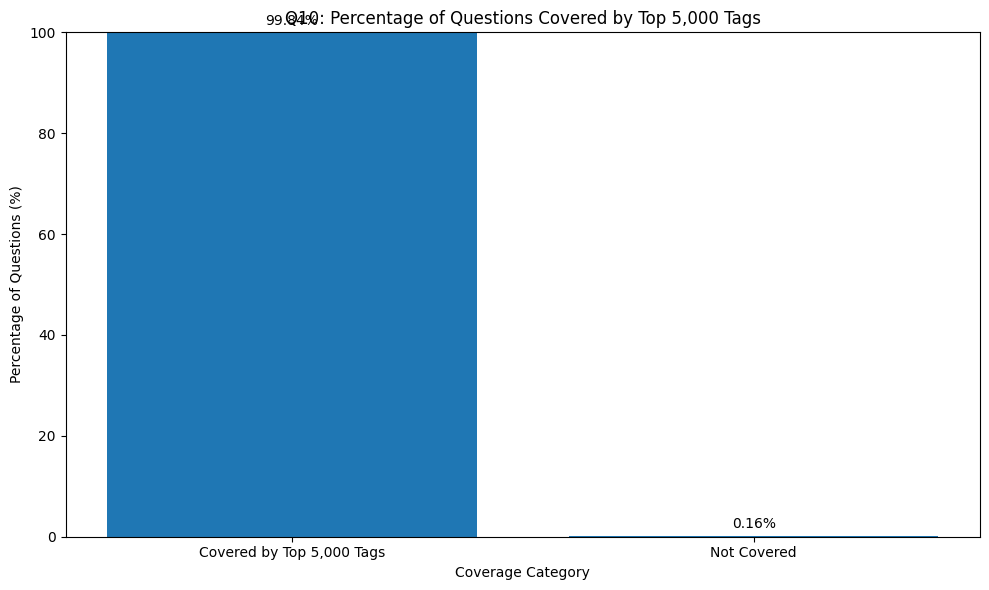

In [37]:

import os
import re
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

BASE_DIR = "/kaggle/working/Arjun_Assignment_data/Arjun_Assignment_data"

POSTS_PATH = os.path.join(
    BASE_DIR,
    "dataset-20210607T020316Z-001/dataset/posts_short.csv"
)

# 1. Load question records
posts = pd.read_csv(
    POSTS_PATH,
    usecols=["id", "post_type_id", "tags"],
    low_memory=False
)

posts["post_type_id"] = pd.to_numeric(
    posts["post_type_id"], errors="coerce"
)

questions = posts[posts["post_type_id"] == 1].copy()

# 2. Extract tags from each question
def extract_tags(value):
    if pd.isna(value):
        return []
    return re.findall(r"<([^<>]+)>", str(value))

questions["tag_list"] = questions["tags"].apply(extract_tags)

# 3. Calculate tag frequencies
tag_frequency = Counter(
    tag
    for tag_list in questions["tag_list"]
    for tag in set(tag_list)
)

# Select the 5,000 most frequent tags
top5000_tags = {
    tag for tag, frequency in tag_frequency.most_common(5000)
}

# 4. Determine which questions are covered
questions["covered_by_top5000"] = questions["tag_list"].apply(
    lambda tags: bool(set(tags) & top5000_tags)
)

total_questions = len(questions)
covered_questions = int(questions["covered_by_top5000"].sum())
uncovered_questions = total_questions - covered_questions

coverage_percentage = (
    covered_questions / total_questions * 100
    if total_questions else 0
)

uncovered_percentage = (
    uncovered_questions / total_questions * 100
    if total_questions else 0
)

# 5. Display results
print("Q10 RESULTS")
print("-" * 45)
print("Total questions:", total_questions)
print("Number of unique tags:", len(tag_frequency))
print("Top tags selected:", len(top5000_tags))
print("Questions covered:", covered_questions)
print("Questions not covered:", uncovered_questions)
print(f"Coverage by top 5,000 tags: {coverage_percentage:.2f}%")
print(f"Not covered: {uncovered_percentage:.2f}%")

# 6. Plot bar chart
categories = [
    "Covered by Top 5,000 Tags",
    "Not Covered"
]

percentages = [
    coverage_percentage,
    uncovered_percentage
]

plt.figure(figsize=(10, 6))
bars = plt.bar(categories, percentages)

plt.title("Q10: Percentage of Questions Covered by Top 5,000 Tags")
plt.xlabel("Coverage Category")
plt.ylabel("Percentage of Questions (%)")
plt.ylim(0, 100)

for bar, value in zip(bars, percentages):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


In [38]:

import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from itertools import combinations

BASE_DIR = "/kaggle/working/Arjun_Assignment_data/Arjun_Assignment_data"

POSTS_PATH = os.path.join(
    BASE_DIR,
    "dataset-20210607T020316Z-001/dataset/posts_short.csv"
)

# Load only required columns from the smaller CSV
questions = pd.read_csv(
    POSTS_PATH,
    usecols=[
        "id", "post_type_id", "creation_date", "score",
        "view_count", "owner_user_id", "tags",
        "answer_count", "comment_count",
        "accepted_answer_id", "favorite_count"
    ],
    low_memory=False
)

# Keep questions, not answers
questions["post_type_id"] = pd.to_numeric(
    questions["post_type_id"], errors="coerce"
)
questions = questions[questions["post_type_id"] == 1].copy()

# Convert numeric fields safely
for col in [
    "id", "score", "view_count", "owner_user_id",
    "answer_count", "comment_count", "favorite_count",
    "accepted_answer_id"
]:
    questions[col] = pd.to_numeric(
        questions[col], errors="coerce"
    )

questions["creation_date"] = pd.to_datetime(
    questions["creation_date"], errors="coerce", utc=True
)

def extract_tags(value):
    if pd.isna(value):
        return []
    return re.findall(r"<([^<>]+)>", str(value))

questions["tag_list"] = questions["tags"].apply(extract_tags)
questions["year"] = questions["creation_date"].dt.year
questions["weekday"] = questions["creation_date"].dt.dayofweek

print("Dataset loaded successfully.")
print("Total question records:", len(questions))
print("Date range:", questions["creation_date"].min(),
      "to", questions["creation_date"].max())
print("Unique question IDs:", questions["id"].nunique())


Dataset loaded successfully.
Total question records: 676204
Date range: 2008-07-31 21:42:52.667000+00:00 to 2018-09-02 05:02:16.480000+00:00
Unique question IDs: 676204


Year with most questions: 2017
Maximum questions: 87417


,Question Count
year,
2008,8308
2009,26141
2010,39683
2011,58404
2012,69149
2013,82366
2014,76322
2015,79091
2016,85194


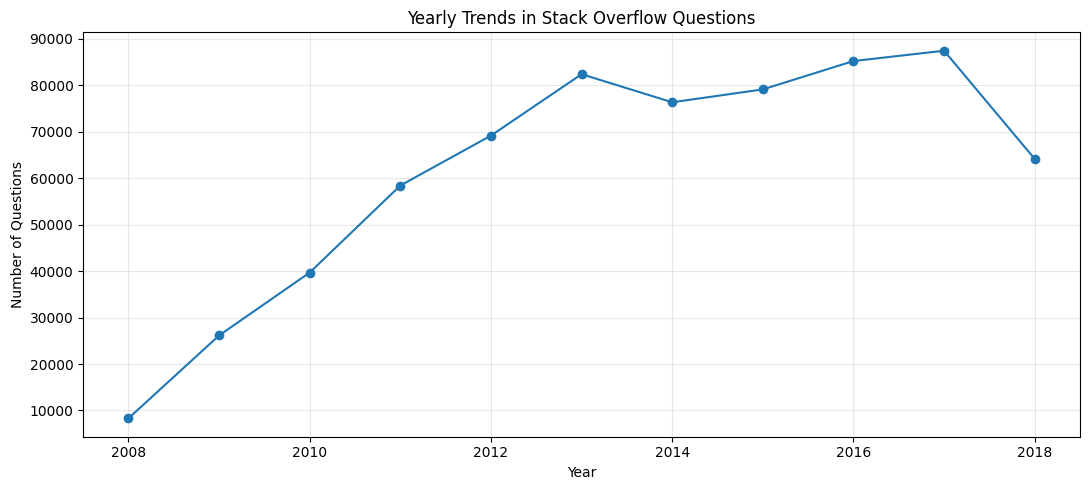

In [39]:

yearly = questions.dropna(subset=["year"]).groupby("year").size()

print("Year with most questions:", yearly.idxmax())
print("Maximum questions:", yearly.max())
display(yearly.rename("Question Count").to_frame())

plt.figure(figsize=(11, 5))
plt.plot(yearly.index, yearly.values, marker="o")
plt.title("Yearly Trends in Stack Overflow Questions")
plt.xlabel("Year")
plt.ylabel("Number of Questions")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Day with most questions: Wednesday


,Question Count
Monday,104698
Tuesday,113396
Wednesday,115591
Thursday,114116
Friday,103753
Saturday,62118
Sunday,62532


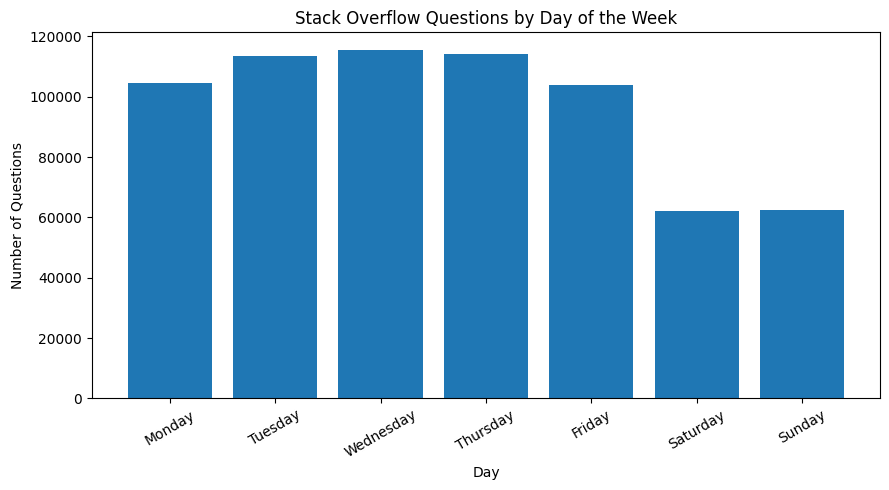

In [40]:

weekday_names = ["Monday", "Tuesday", "Wednesday", "Thursday",
                 "Friday", "Saturday", "Sunday"]

weekday_counts = (
    questions.dropna(subset=["weekday"])
    .groupby("weekday").size()
    .reindex(range(7), fill_value=0)
)

weekday_counts.index = weekday_names

print("Day with most questions:", weekday_counts.idxmax())
display(weekday_counts.rename("Question Count").to_frame())

plt.figure(figsize=(9, 5))
plt.bar(weekday_counts.index, weekday_counts.values)
plt.title("Stack Overflow Questions by Day of the Week")
plt.xlabel("Day")
plt.ylabel("Number of Questions")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


,question_count,unanswered_count,unanswered_rate
tag_list,,,
pandas-groupby,111,56,50.45
scenebuilder,129,65,50.39
jsf-2.2,211,105,49.76
borrow-checker,117,56,47.86
mariadb,156,73,46.79
python-3.6,183,83,45.36
firebase-storage,157,71,45.22
pyqt5,202,91,45.05
google-cloud-firestore,296,126,42.57


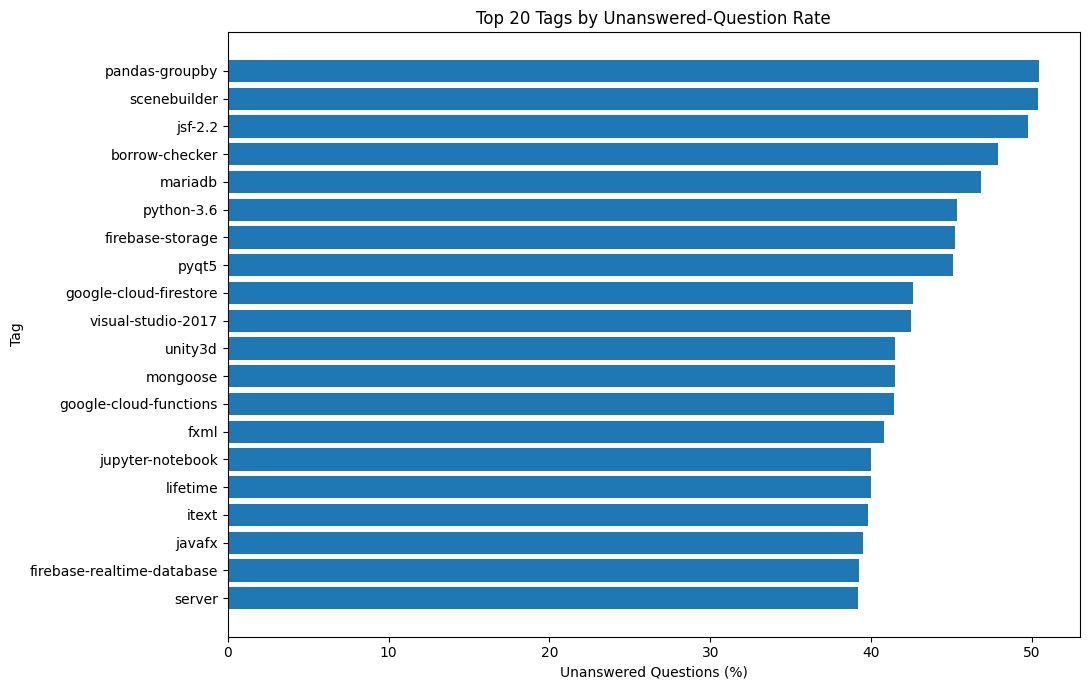

In [41]:

answer_data = questions[
    questions["answer_count"].notna()
].explode("tag_list").dropna(subset=["tag_list"])

answer_data["unanswered"] = answer_data["answer_count"] == 0

unanswered_stats = answer_data.groupby("tag_list").agg(
    question_count=("id", "nunique"),
    unanswered_count=("unanswered", "sum")
)

unanswered_stats = unanswered_stats[
    unanswered_stats["question_count"] >= 100
].copy()

unanswered_stats["unanswered_rate"] = (
    unanswered_stats["unanswered_count"] /
    unanswered_stats["question_count"] * 100
)

top_unanswered = unanswered_stats.nlargest(
    20, "unanswered_rate"
)

display(top_unanswered.round(2))

plt.figure(figsize=(11, 7))
plt.barh(
    top_unanswered.index[::-1],
    top_unanswered["unanswered_rate"].iloc[::-1]
)
plt.title("Top 20 Tags by Unanswered-Question Rate")
plt.xlabel("Unanswered Questions (%)")
plt.ylabel("Tag")
plt.tight_layout()
plt.show()


,Question Count
owner_user_id,
179736,144
651174,117
4653,113
49153,113
39677,108
496949,101
51816,99
65387,97
156458,97


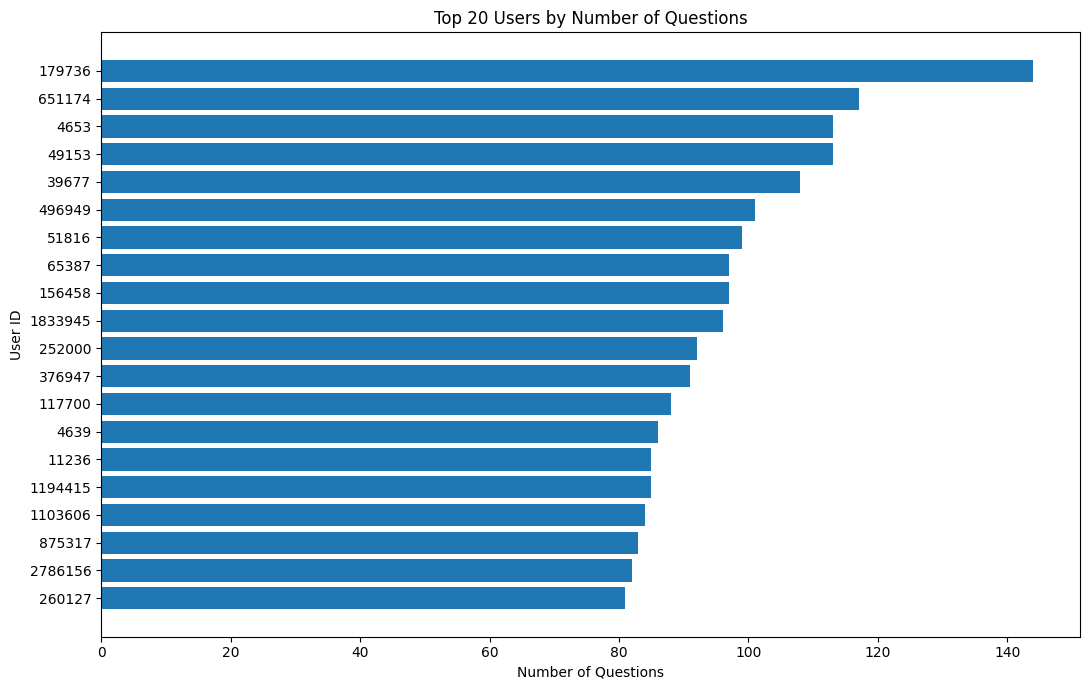

In [43]:

user_data = questions.dropna(subset=["owner_user_id"]).copy()

user_data = user_data[user_data["owner_user_id"] > 0]

user_counts = (
    user_data.groupby("owner_user_id")["id"]
    .nunique()
    .sort_values(ascending=False)
    .head(20)
)

display(user_counts.rename("Question Count").to_frame())

plt.figure(figsize=(11, 7))
plt.barh(
    user_counts.index.astype(str)[::-1],
    user_counts.values[::-1]
)
plt.title("Top 20 Users by Number of Questions")
plt.xlabel("Number of Questions")
plt.ylabel("User ID")
plt.tight_layout()
plt.show()


,Tag Pair,Question Count
0,javascript + jquery,21301
1,css + html,13985
2,mysql + php,13354
3,html + javascript,12614
4,.net + c#,10955
5,android + java,10707
6,ios + objective-c,6998
7,html + jquery,6845
8,python + python-3.x,6538
9,ios + swift,6087


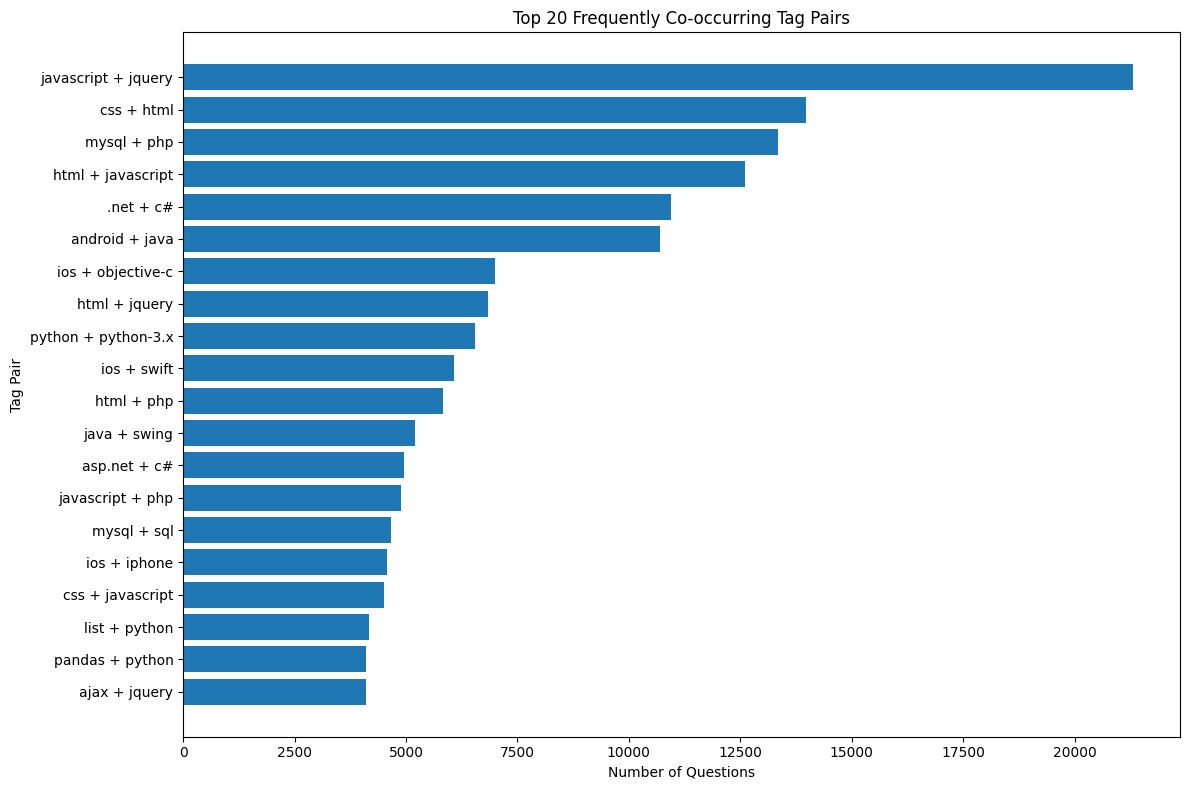

In [44]:

pair_counts = Counter()

# Each tag pair is counted once per question.
for tags in questions["tag_list"]:
    unique_tags = sorted(set(tags))
    for pair in combinations(unique_tags, 2):
        pair_counts[pair] += 1

top_pairs = pair_counts.most_common(20)

pair_df = pd.DataFrame(
    [
        {
            "Tag Pair": f"{tag1} + {tag2}",
            "Question Count": count
        }
        for (tag1, tag2), count in top_pairs
    ]
)

display(pair_df)

if not pair_df.empty:
    plt.figure(figsize=(12, 8))
    plt.barh(
        pair_df["Tag Pair"][::-1],
        pair_df["Question Count"][::-1]
    )
    plt.title("Top 20 Frequently Co-occurring Tag Pairs")
    plt.xlabel("Number of Questions")
    plt.ylabel("Tag Pair")
    plt.tight_layout()
    plt.show()
else:
    print("No tag pairs were found.")
